In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import scipy.stats as stats

%matplotlib inline

In [2]:
#importando dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1 - Analyzing Best-Seller Trends Across Product Categories

#### 1. Crosstab Analysis:

In [3]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
#proporcion de best-sellers by category
prop = crosstab_result.div(crosstab_result.sum(axis=1), axis=0)
prop

#best proportion
prop_best = prop[True].sort_values(ascending=False)
prop_best.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: True, dtype: float64

grocery estaria en la primera posicion en los best-seller con 0.058135 de proporcion 

#### 2. Statistical Tests:

In [5]:
#Chi-square 
chi2, p, dof, expected = chi2_contingency(crosstab_result)
chi2, p 

# p=0.0 -> es dependecia estadistica

(36540.20270061387, 0.0)

In [6]:
# Cramér's V
association(crosstab_result, method='cramer')

#como esta entre 0.1-0.3 es moderada aunque es baja en moderada

0.1222829439760564

#### Visualizations

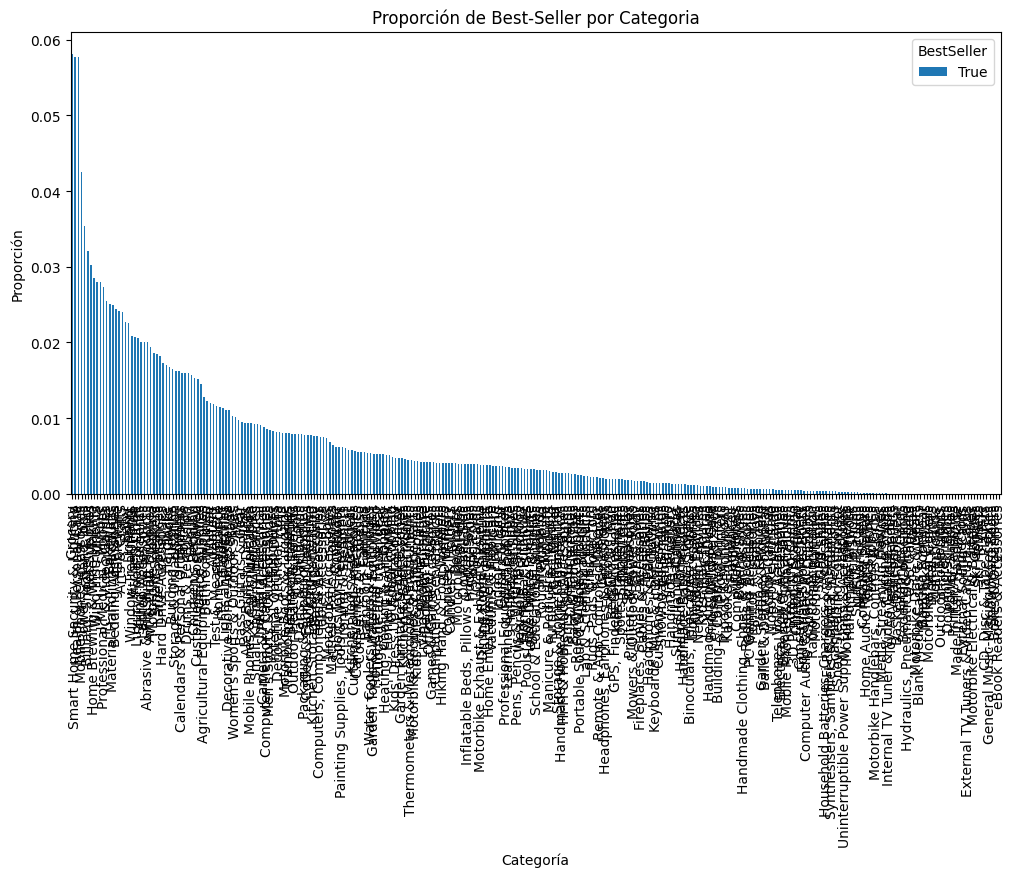

In [7]:
#stecked bar chart
crosstab_norm = crosstab_result.div(crosstab_result.sum(axis=1), axis=0)

prop_best.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Proporción de Best-Seller por Categoria")
plt.ylabel("Proporción")
plt.xlabel("Categoría")
plt.legend(title='BestSeller')
plt.show()

## Part 2- Exploring Product Prices and Ratings Across Categories and Brands

In [8]:
#0. Quitar Outliers en product prices
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - (1.5*IQR)
upper = Q3 + (1.5*IQR)

df_no_outliers = df[(df["price"] >= lower) & (df["price"] <= upper)]


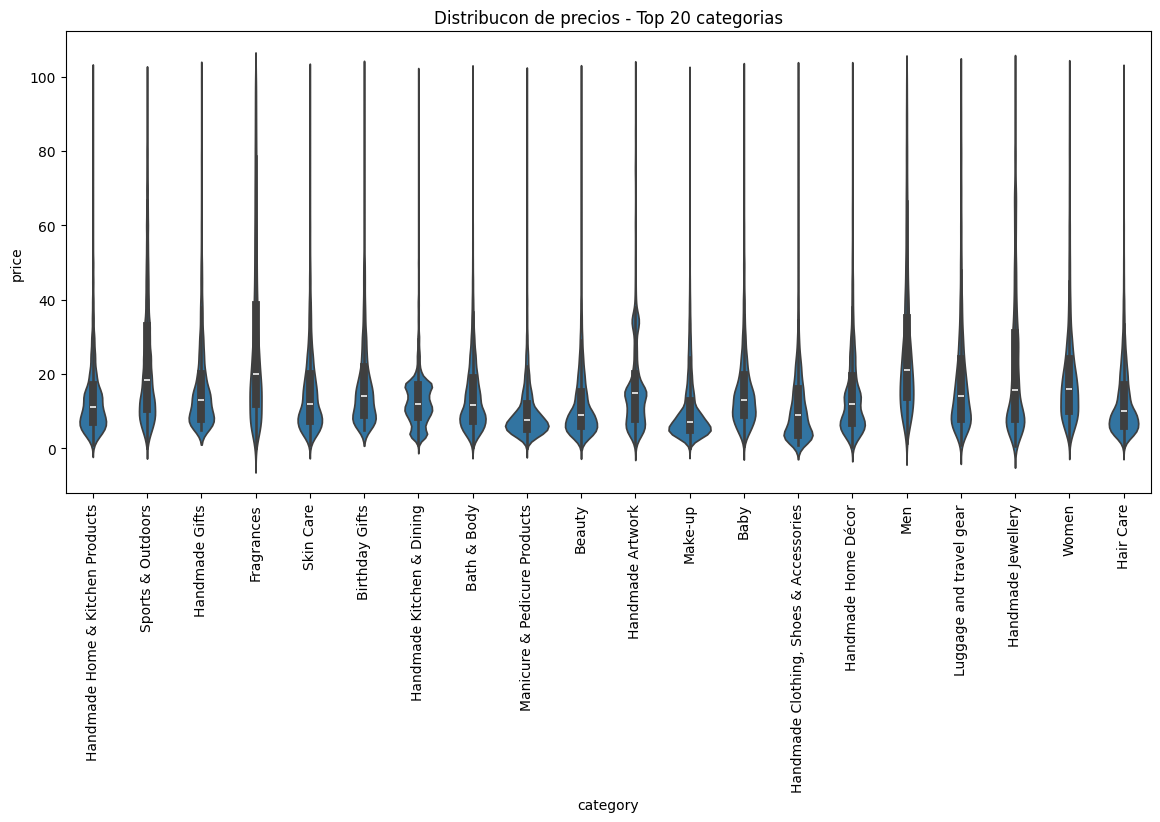

In [9]:
#Violin plot
top20 = df_no_outliers['category'].value_counts().head(20).index

plt.figure(figsize=(14,6))

sns.violinplot(data=df_no_outliers[df_no_outliers['category'].isin(top20)], x='category', y='price')
plt.xticks(rotation=90)
plt.title("Distribucon de precios - Top 20 categorias")
plt.show()

In [10]:
#Categoria con mediana mayor
df_no_outliers.groupby("category")['price'].median().sort_values(ascending=False).head()

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

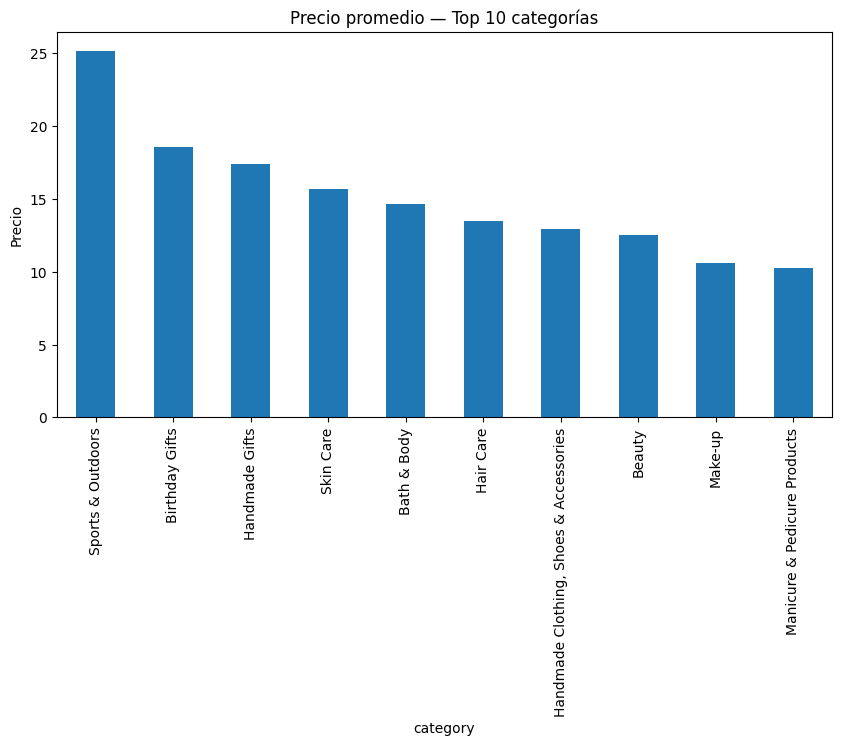

In [11]:
# Bar chart 
top10 = df_no_outliers["category"].value_counts().head(10).index

avg_price = (df_no_outliers[df_no_outliers["category"].isin(top10)]
    .groupby("category")["price"].mean().sort_values(ascending=False))

avg_price.plot(kind="bar", figsize=(10,5))
plt.title("Precio promedio — Top 10 categorías")
plt.ylabel("Precio")
plt.show()


In [12]:
#Media sin filtrar por categoria
df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False).head()

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

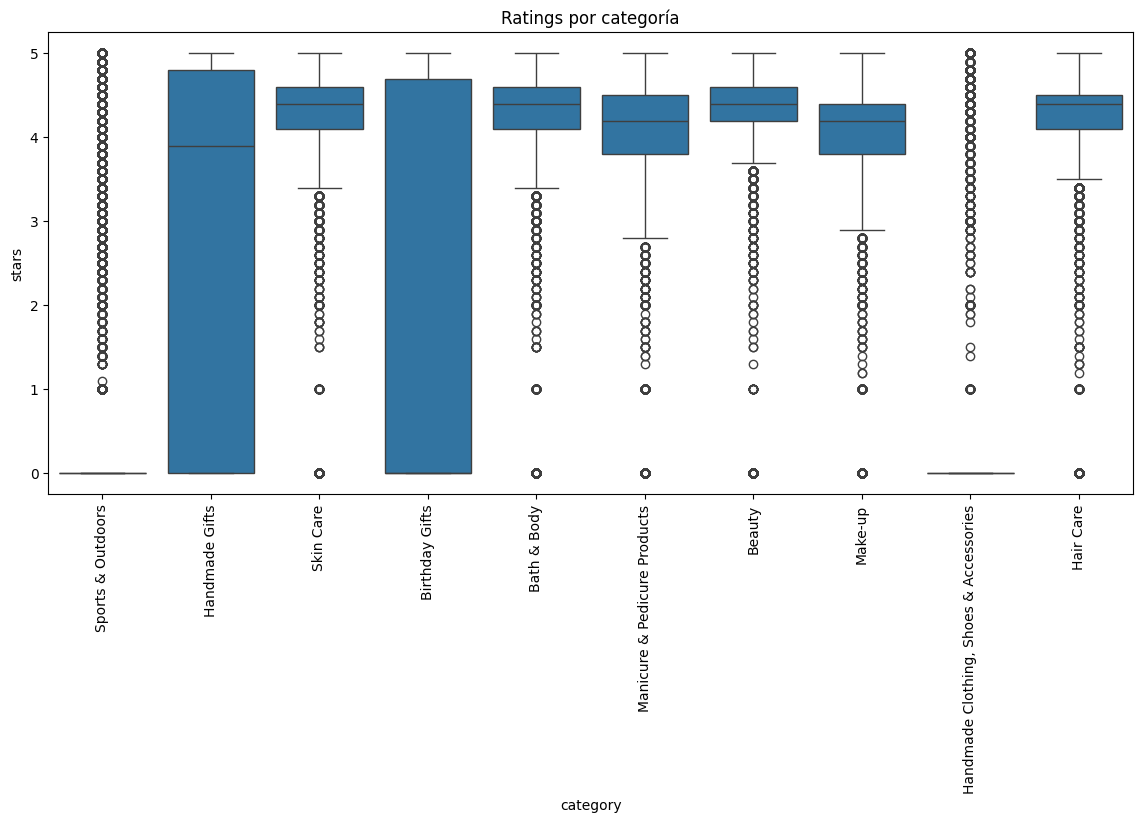

In [13]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top10)],
    x="category",
    y="stars"
)

plt.xticks(rotation=90)
plt.title("Ratings por categoría")
plt.show()

In [14]:
df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False).head()

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

## Part 3 - Previo vs Rating

In [15]:
df_no_outliers[["price","stars"]].corr()

,price,stars
price,1.000000,-0.077673
stars,-0.077673,1.000000


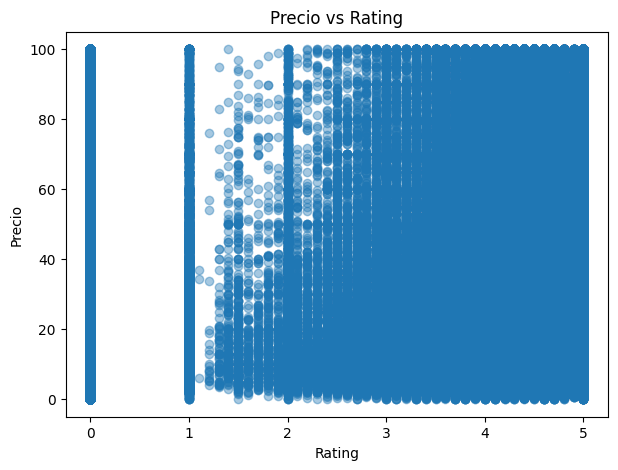

In [16]:
plt.figure(figsize=(7,5))

plt.scatter(df_no_outliers["stars"],df_no_outliers["price"],alpha=0.4)

plt.xlabel("Rating")
plt.ylabel("Precio")
plt.title("Precio vs Rating")
plt.show()

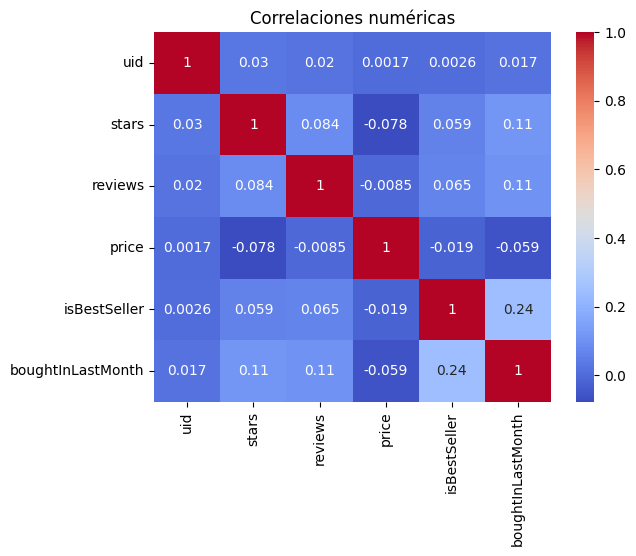

In [17]:
sns.heatmap(df_no_outliers.corr(numeric_only=True), annot=True,cmap="coolwarm")
plt.title("Correlaciones numéricas")
plt.show()

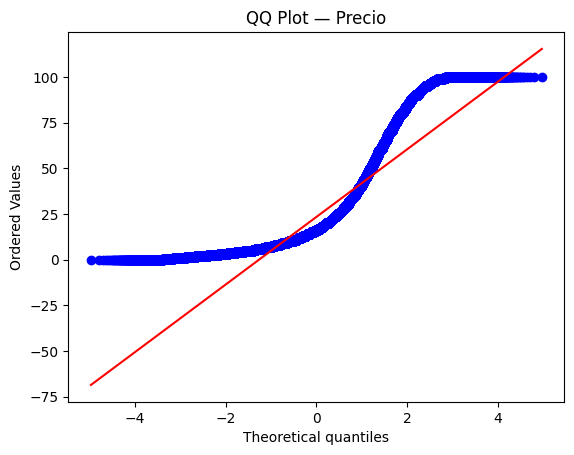

In [18]:
stats.probplot(df_no_outliers["price"], plot=plt)
plt.title("QQ Plot — Precio")
plt.show()